# Прогнозирование вероятности клика на рекламное объявление с использованием машинного обучения

- Автор: Усиков Даниил
- Дата: 14.09.2026

### Цели и задачи проекта

**Цель**: Построить модель бинарной классификации, которая предсказывает вероятность клика — показатель CTR — на рекламное объявление.

**Задачи**:

1. Подготовить среду, библиотеки и загрузить данные
2. Провести первичный анализ данных
3. Разделить данные на выборки
4. Предобработать данные
5. Отбрать признаки
6. Обучить базовые модели
7. Обучить модели
8. Подбрать гиперпараметры
9. Выбрать и обучить финальную модель
10. Калибровать модель
11. Оценить качество калибровки
12. Написать финальный отчёт и выводы
13. Сохранить модель для продакшена

### Описание данных

Для анализа используются данные, собранные из систем показа рекламы и логирования взаимодействий пользователей с рекламными баннерами компании Advandex за фиксированный временной промежуток. Данные хранятся в CSV-файле `ds_s16_ad_click_dataset.csv`.

**`ds_s16_ad_click_dataset` содержит**:
1. **Идентификаторы и временные метки**:
- `id` — уникальный идентификатор записи о показе баннера;
- `hour` — час, в который был показан баннер, в формате YYMMDDHH.
2. **Характеристики рекламной площадки ( Site )**:
- `site_id` — идентификатор веб-сайта, на котором был показан баннер;
- `site_domain` — домен веб-сайта;
- `site_category` — тематическая категория веб-сайта.
3. **Характеристики рекламируемого приложения ( App )**:
- `app_id` — идентификатор рекламируемого мобильного приложения;
- `app_domain` — домен рекламируемого приложения;
- `app_category` — категория рекламируемого приложения.
4. **Характеристики устройства и соединения пользователя**:
- `device_id` — идентификатор браузера или устройства;
- `device_ip` — IP-адрес устройства;
- `device_model` — модель устройства;
- `device_type` — тип устройства пользователя: например, смартфон, планшет, ПК;
- `device_conn_type` — тип сетевого соединения устройства: например, Wi-Fi, 3G, 4G.
5. **Характеристики рекламного баннера и аукциона**:
- `C1` — анонимизированный признак, характеризующий контекст показа;
- `banner_pos` — позиция баннера на веб-странице;
- `C14 — C21` — группа анонимизированных признаков, описывающих параметры баннера, пользователя или аукциона.
6. **Машинно-сгенерированные признаки (ML Features)**:
- `ml_feature_1`, `ml_feature_3` — `ml_feature_6`, `ml_feature_8` — `ml_feature_10` — числовые признаки, полученные в результате предварительной обработки и генерации новых признаков;
- `ml_feature_2`, `ml_feature_7` — категориальные признаки, полученные в результате предварительной обработки и генерации новых признаков.
7. **Целевая переменная:**
- `click` — бинарный признак, указывающий, был ли совершён клик по баннеру. 1 — клик был, 0 — клика не было.

# Структура проекта

## 1. Подготовка среды и загрузка данных

#### 1.1 Подготовьте библиотеки
- Создайте файл `requirements.txt` с фиксированными версиями всех пакетов.
- Импортируйте все необходимые библиотеки.
- Настройте параметры отображения графиков и датафреймов.

#### 1.2 Зафиксируйте константу для воспроизводимости
- Установите константу `RANDOM_SEED`.
- Применяйте её ко всем алгоритмам, которые её поддерживают.

#### 1.3 Загрузите данные
- Прочитайте CSV-файл с данными. Путь к файлу: `'/datasets/ds_s16_ad_click_dataset.csv'`
- Выведите размер датасета, первые несколько строк и информацию о типах столбцов.
- Проверьте успешность загрузки данных.

In [1]:
!pip install phik
!pip install --upgrade scikit-learn

In [2]:
# Импортируем библиотеки
# Библиотеки для работы с данными
import pandas as pd
import numpy as np

# Библиотеки для сохранения модели
import joblib

# Библиотеки для построения графиков
import matplotlib.pyplot as plt
import seaborn as sns

# Библиотека для построения матрицы корреляции
from phik import phik_matrix

# Библиотеки для работы с моделью
from sklearn.calibration import CalibratedClassifierCV, calibration_curve, CalibrationDisplay 
from sklearn.feature_selection import (
    SequentialFeatureSelector,
    VarianceThreshold
)
from sklearn.feature_selection import RFE
from sklearn.frozen import FrozenEstimator
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    train_test_split,
    cross_validate
)
from sklearn.dummy import DummyClassifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer, TargetEncoder
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    recall_score,
    f1_score,
    precision_score,
    average_precision_score,
    brier_score_loss,
    classification_report,
    log_loss,
    precision_recall_curve,
    auc,
    roc_auc_score
)

In [3]:
# Установим константу для воспроизводимости
RANDOM_SEED = 42

In [4]:
# Выгружаем датасет
ad = pd.read_csv('data/ad_dataset_sample.csv')

In [5]:
# Выведем информацию о датасете
ad.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 34 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                2000 non-null   float64
 1   click             2000 non-null   int64  
 2   hour              2000 non-null   int64  
 3   C1                2000 non-null   int64  
 4   banner_pos        2000 non-null   int64  
 5   site_id           2000 non-null   object 
 6   site_domain       2000 non-null   object 
 7   site_category     2000 non-null   object 
 8   app_id            2000 non-null   object 
 9   app_domain        2000 non-null   object 
 10  app_category      2000 non-null   object 
 11  device_id         2000 non-null   object 
 12  device_ip         2000 non-null   object 
 13  device_model      2000 non-null   object 
 14  device_type       2000 non-null   int64  
 15  device_conn_type  2000 non-null   int64  
 16  C14               2000 non-null   int64  


In [6]:
# Выведем несколько первых строк
ad.head()

,id,click,hour,C1,banner_pos,site_id,site_domain,site_category,app_id,app_domain,...,ml_feature_1,ml_feature_2,ml_feature_3,ml_feature_4,ml_feature_5,ml_feature_6,ml_feature_7,ml_feature_8,ml_feature_9,ml_feature_10
0,1.668993e+19,0,14102801,1005,0,1fbe01fe,f3845767,28905ebd,ecad2386,7801e8d9,...,-0.491704,D,6.052878,0,0.349830,-0.347298,Z,-0.488264,-0.083169,-0.354750
1,2.169899e+18,0,14102213,1005,0,b99a2c43,cc962a1f,f028772b,ecad2386,7801e8d9,...,-0.366791,A,-8.457409,1,-0.545775,-0.178054,Y,-0.241444,-0.280068,-0.037999
2,1.324544e+19,0,14102101,1005,0,1fbe01fe,f3845767,28905ebd,ecad2386,7801e8d9,...,1.171162,A,2.007125,1,-0.755648,0.969194,Z,-0.918971,-0.270175,-0.398037
3,1.790973e+19,1,14102304,1005,0,6c5b482c,7687a86e,3e814130,ecad2386,7801e8d9,...,0.384406,E,1.128266,1,-1.189701,-0.795049,X,0.771242,-0.345220,0.459868
4,6.461663e+18,1,14102820,1005,0,85f751fd,c4e18dd6,50e219e0,9c13b419,2347f47a,...,-0.109215,E,-2.046459,0,0.444530,0.711716,Y,0.919011,0.773062,-0.326914


Данные загружены успешно.

## Исследовательский анализ данных (EDA)

#### Опишите базовую информацию о датасете
- Определите, сколько объектов и признаков содержится в данных.
- Выясните, какие типы данных представлены (числовые, категориальные).
- Дайте общее описание: укажите, что известно о пользователях и рекламе.

#### Анализ целевой переменной
- Проанализируйте, как распределена целевая переменная.
- Определите, есть ли дисбаланс классов. Это важно для выбора метрик.
- Посчитайте долю рекламы, на которую кликнули, и долю рекламы, на которую не кликнули.

#### Анализ признаков
- Определите, все ли признаки нужны для обучения модели. Есть ли среди них явно бесполезные?
- Опишите, какие признаки категориальные, а какие — числовые.
- Проведите первичный отбор: удалите ненужные признаки.

#### Анализ пропущенных значений
- Проверьте долю пропусков в каждом признаке.
- Выберите корректную стратегию для заполнения пропусков — удаление, среднее, медиана, мода. Выбор обоснуйте.

#### Анализ категориальных признаков
- Определите, сколько уникальных значений в каждом категориальном признаке.
- Укажите, какие признаки можно кодировать One-Hot Encoding, а какие требуют специальных методов из-за высокой кардинальности.

#### Анализ выбросов и распределений
- Проверьте, есть ли явные выбросы в числовых признаках.
- Опишите, как распределены выбросы — нормально, асимметрично, каким-то другим образом.

#### Корреляции
- Определите, какие признаки коррелируют с целевой переменной.
- Выявите сильно скоррелированные признаки, которые можно удалить, если такие есть.

#### Выводы по EDA
- Кратко опишите ключевые находки.
- Выберите признаки, которые выглядят наиболее перспективными для модели. Выбор обоснуйте.
- Определите действия по предобработке данных, которые необходимо проделать.

### Описание базовой информации о датасете

Датасет состоит из 50000 строк и 34 столбцов(признаков). В данных представлена информация о рекламной площадке, рекламирующем приложении, усройстве и соединении пользователя, характеристиках рекламного банера и машинно-сгенерированные признаки.

- Названия столбцов приведены к общему стилю кроме названий характеристик рекламного банера, которые названы так не случайно.
- В датасете присутствуют и числовые, и категориальные данные. Типы данных выбраны правильно и соответствуют описанию. Но стоило бы поменять тип данных столбца `hour`.
- Пропуски в данных отсутствуют.

На первый взгляд данные соответствуют описанию.

In [7]:
# Превращаем формат YYMMDDHH в полноценный объект datetime

datetime_series = pd.to_datetime(ad['hour'], format='%y%m%d%H')
# Извлекаем полезные признаки для модели
ad['hour_of_day'] = datetime_series.dt.hour

# Удаляем старый сырой столбец hour
ad = ad.drop(columns=['hour'])

Так как данные всего за 10 дней, день выделять не будем и оставим только час.

### Анализ целевой переменной

Целевая переменная - `click`. Проанализируем ее распределение, исследуем, есть ли дисбаланс.

In [8]:
# Выведем распределение целевой переменной
ad['click'].value_counts()

click
0    1647
1     353
Name: count, dtype: int64

In [9]:
# Выведем долю рекламы на которую не кликнули
ad['click'].value_counts(normalize=True)

click
0    0.8235
1    0.1765
Name: proportion, dtype: float64

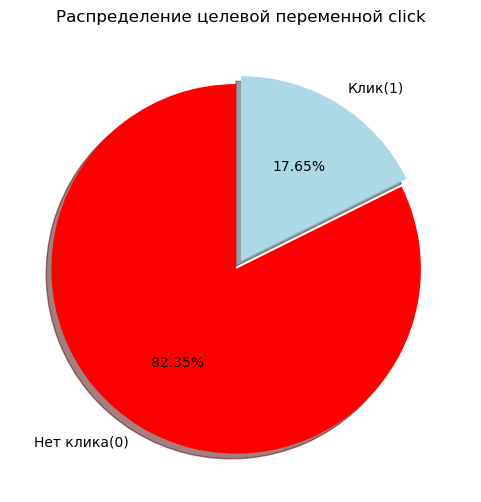

In [10]:
# Строим график распределение целевой переменной
plt.figure(figsize=(6,6))
plt.pie(
    ad['click'].value_counts(),
    labels=['Нет клика(0)', 'Клик(1)'],
    autopct='%1.2f%%',
    startangle=90,
    colors=['Red', 'lightblue'],
    shadow=True,
    explode=(0.05, 0)
)
plt.title('Распределение целевой переменной click')
plt.show()

Целевая переменная принимает значения только 0 и 1. В значения замечен сильный дисбаланс, только в 17.21% случаев показа рекламы происходил клик, поэтому в проекте будет использоваться PR-AUC, которая адекватно оценивает качество моделей на несбалансированных данных. В значениях целевой переменной отсутствуют пропуски.

### Анализ признаков

Описание признаков, их важности, есть ли признаки, которые можно удалить.

- `id` — категориальный. Не несет ценности для прогнозирования.
- `site_id` — категориальный. Частная информация о сайте. Важность зависит от количества одинаковых значений id в таблице.
- `site_domain` — категориальный. Частная информация о сайте. Важность зависит от количества одинаковых значений домена в таблице.
- `site_category` — категориальный. Общая информация о сайте.
- `app_id` — категориальный. Частная информация о приложении. Важность зависит от количества одинаковых значений id в таблице.
- `app_domain` — категориальный. Частная информация о приложении. Важность зависит от количества одинаковых значений домена в таблице.
- `app_category` — категориальный. Частная информация о сайте.
- `device_id` — категориальный. Слишком большая вариативность, нужно удалить.
- `device_ip` — категориальный. Слишком большая вариативность, нужно удалить.
- `device_model` — категориальный. Может указывать на латежеспособность пользователя.
- `device_type` — числовой. Тип устройства. Важно оставить.
- `device_conn_type` — числовой. Тип соединения может влиять на клик. Wi-fi пользуются в помещения, а 3G и 4G обычно пользуются, находясь на улице и в меньшем комфорте.
- `C1` — числовой. Контекст показа важно оставить.
- `banner_pos` — числовой. Позицию банера важно оставить.
- `C14 — C21` — числовые. Параметры банера важно оставить.
- `ml_feature_1`, `ml_feature_3` — `ml_feature_6`, `ml_feature_8` — `ml_feature_10` — числовые. Новые признаки могут быть важны.
- `ml_feature_2`, `ml_feature_7` — категориальные. Новые признаки могут быть важны.
- `click` — числовой. Целевая переменная.
- `hour_of_day` - числовой. Указывает на суточное поведение пользователя.

Удаляем: `id`, `device_id`, `device_ip`.

In [11]:
# Перепроверим распределение перед удалением
ad['device_id']. value_counts()

device_id
a99f214a    1626
a32c7f83       1
d23763ec       1
4d93ca43       1
71b25594       1
            ... 
2c0fae95       1
de01faee       1
a8f78d57       1
cfd5e1da       1
2df78cd8       1
Name: count, Length: 375, dtype: int64

In [12]:
# Перепроверим распределение перед удалением
ad['device_ip']. value_counts()

device_ip
d90a7774    12
6b9769f2    11
431b3174     9
6394f6f6     6
c6563308     6
            ..
95115fec     1
df80eb4a     1
0e85452c     1
b1f6e0f6     1
b45b2e53     1
Name: count, Length: 1887, dtype: int64

- `device_id` имеет гигантское «аномальное» значение (a99f214a, которое встречается аж 41 213 раз из 50 000 — скорее всего, это заглушка для неизвестных или десктопных устройств), а дальше идет длинный хвост редких уникальных ID.
- `device_ip` также разбит на огромное число уникальных значений (41 455 уникальных IP на 50 000 строк), где большинство встречается по 1 разу.

Перед удалением id нужно проверить на явные и неявные дубликаты.

In [13]:
# Проверим данные на явные дубликаты
ad.duplicated().sum()

np.int64(0)

In [14]:
# Проверим данные на неявные дубликаты
ad['id'].value_counts()

id
1.668993e+19    1
6.731395e+18    1
9.027459e+18    1
1.771482e+19    1
3.522697e+18    1
               ..
5.370249e+18    1
1.434125e+19    1
2.414922e+18    1
5.510555e+18    1
4.007667e+18    1
Name: count, Length: 2000, dtype: int64

In [15]:
# Удаляем ненужные столбцы
ad = ad.drop(columns=['id', 'device_id', 'device_ip'])

### Анализ пропущенных значений

Проверим долю пропусков в каждом признаке и выберем корректную стратегию.

In [16]:
# Проверим количество пропусков
ad.isna().mean()

click               0.0
C1                  0.0
banner_pos          0.0
site_id             0.0
site_domain         0.0
site_category       0.0
app_id              0.0
app_domain          0.0
app_category        0.0
device_model        0.0
device_type         0.0
device_conn_type    0.0
C14                 0.0
C15                 0.0
C16                 0.0
C17                 0.0
C18                 0.0
C19                 0.0
C20                 0.0
C21                 0.0
ml_feature_1        0.0
ml_feature_2        0.0
ml_feature_3        0.0
ml_feature_4        0.0
ml_feature_5        0.0
ml_feature_6        0.0
ml_feature_7        0.0
ml_feature_8        0.0
ml_feature_9        0.0
ml_feature_10       0.0
hour_of_day         0.0
dtype: float64

В данных не было замечено пропусков. Заполнять или удалять их не понадобится.

### Анализ категориальных признаков

Определим, сколько уникальных значений в каждом категориальном признаке. Укажим, какие признаки можно кодировать OHE, а какие требуют специальных методов.

In [17]:
# Выделим категориальные признаки
cat_columns = ad.select_dtypes(include=['object']).columns

In [18]:
# Выведем количество уникальных значений
for column in cat_columns:
    print(f'Количество уникальных значений столбца {column}: {ad[column].nunique()}')

Количество уникальных значений столбца site_id: 240
Количество уникальных значений столбца site_domain: 199
Количество уникальных значений столбца site_category: 12
Количество уникальных значений столбца app_id: 174
Количество уникальных значений столбца app_domain: 23
Количество уникальных значений столбца app_category: 10
Количество уникальных значений столбца device_model: 607
Количество уникальных значений столбца ml_feature_2: 5
Количество уникальных значений столбца ml_feature_7: 3


**Для One-Hot Encoding (низкая кардинальность):**
- `site_category` (18 значений)
- `app_category` (22 значения)
- `ml_feature_2` (5 значений)
- `ml_feature_7` (3 значения)

**Для специальных методов (высокая кардинальность):**
- `app_domain` (67 значений)
- `site_id` (1160 значений)
- `site_domain` (1013 значений)
- `app_id` (976 значений)
- `device_model` (2521 значений)

### Анализ выбросов и распределений

Проверим есть ли явные выбросы в числовых признаках и опишем как распределены выбросы.

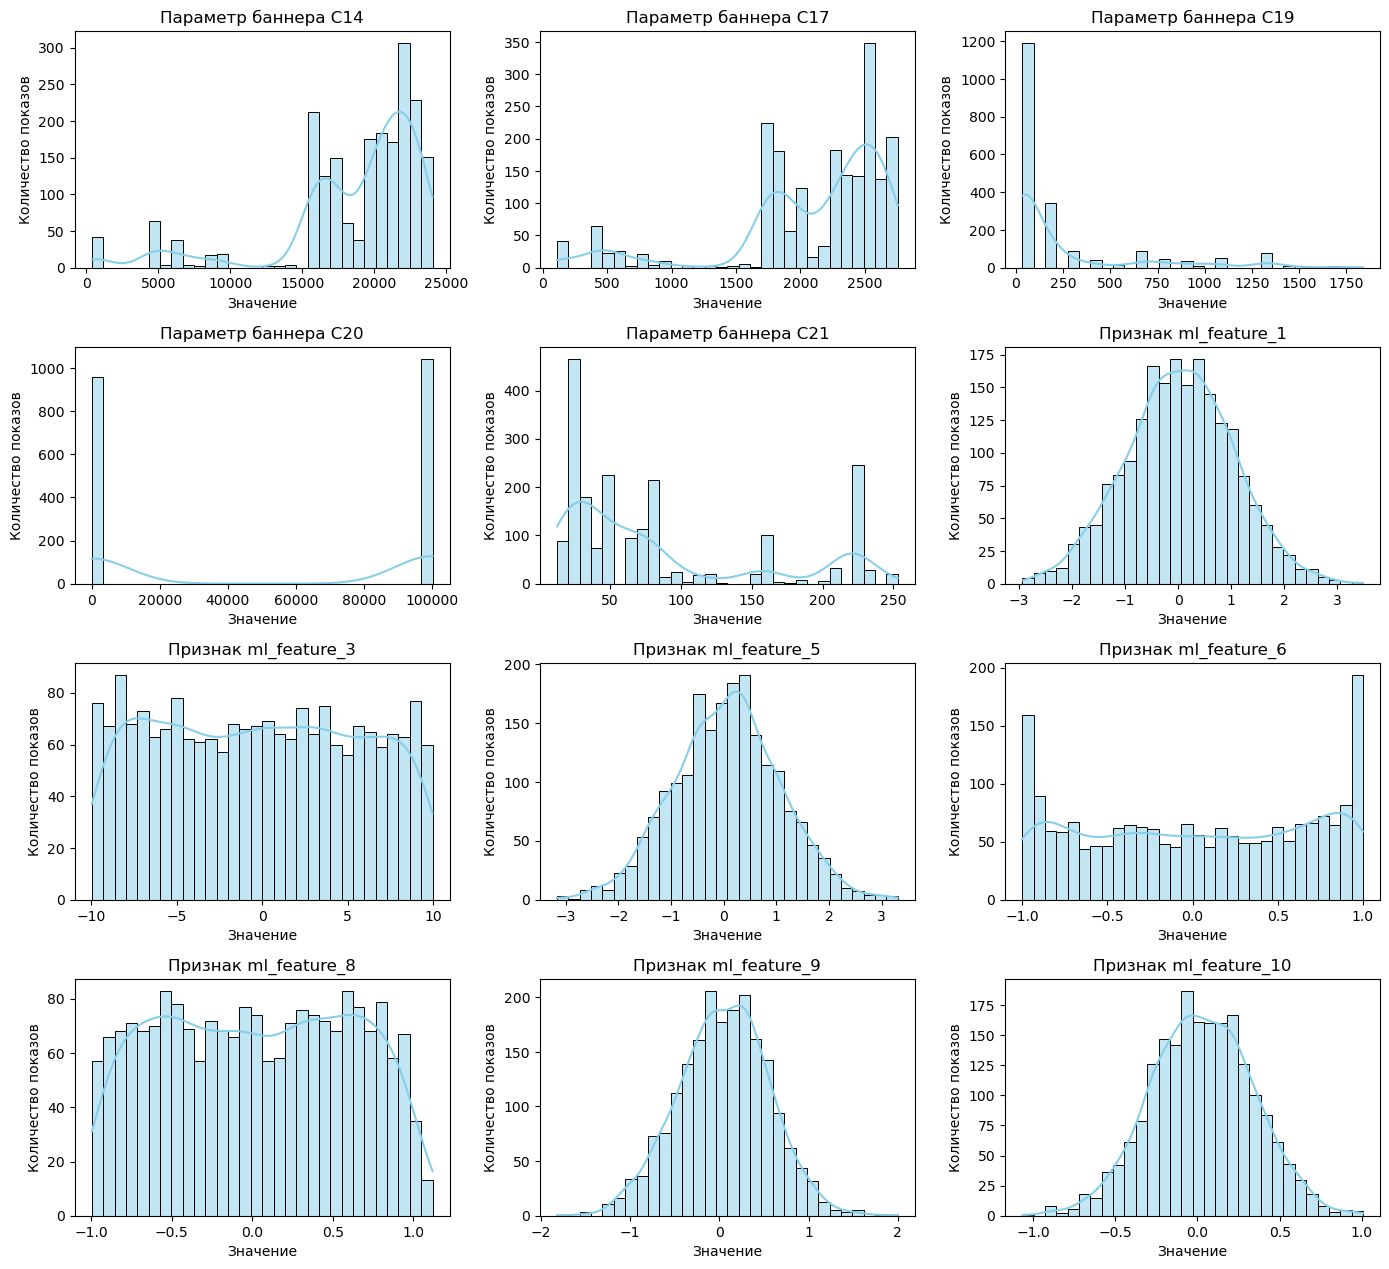

In [19]:
# Выделим числовые признаки
num_columns = ad.select_dtypes(include=['int64', 'float64', 'int32']).columns

# Непрерывные признаки
continuous_cols = ['C14', 'C17','C19',
    'C20', 'C21', 'ml_feature_1', 
    'ml_feature_3', 'ml_feature_5', 'ml_feature_6', 
    'ml_feature_8', 'ml_feature_9', 'ml_feature_10'
]

# Дискретные признаки
discrete_cols = [
    'hour_of_day', 'banner_pos', 'device_type', 
    'device_conn_type',
    'C1', 'C15', 'C16',
    'C18', 'ml_feature_4'
]

# Построим графики распределения числовых признаков
labels_dict = {
    'click' : ['Клик', 'Клик(1) / не клик(0)', 'Количество показов'],
    'hour_of_day': ['Час дня', 'Час (0-23)', 'Количество показов'],
    'banner_pos': ['Позиция баннера', 'Позиция', 'Количество показов'],
    'C1': ['Контекстный параметр C1', 'Значение C1', 'Количество показов'],
    'C14': ['Параметр баннера C14', 'Значение', 'Количество показов'],
    'C15': ['Ширина баннера (C15)', 'Пиксели', 'Количество показов'],
    'C16': ['Высота баннера (C16)', 'Пиксели', 'Количество показов'],
    'C17': ['Параметр баннера C17', 'Значение', 'Количество показов'],
    'C18': ['Параметр баннера C18', 'Значение', 'Количество показов'],
    'C19': ['Параметр баннера C19', 'Значение', 'Количество показов'],
    'C20': ['Параметр баннера C20', 'Значение', 'Количество показов'],
    'C21': ['Параметр баннера C21', 'Значение', 'Количество показов'],
    'device_type': ['Тип устройства', 'Тип', 'Количество показов'],
    'device_conn_type': ['Тип соединения', 'Тип', 'Количество показов']
}

for col in num_columns:
    if 'ml_feature' in col and col not in labels_dict:
        labels_dict[col] = [f'Признак {col}', 'Значение', 'Количество показов']

# Строим гистограммы
plt.figure(figsize=(14, 25))
for i, col in enumerate(continuous_cols, 1):
    plt.subplot(8, 3, i)
    sns.histplot(ad[col], bins=30, kde=True, color='skyblue')
    if col in labels_dict:
        title, xlabel, ylabel = labels_dict[col]
        plt.title(title)
        plt.xlabel(xlabel)
        plt.ylabel(ylabel)

plt.tight_layout()
plt.show()

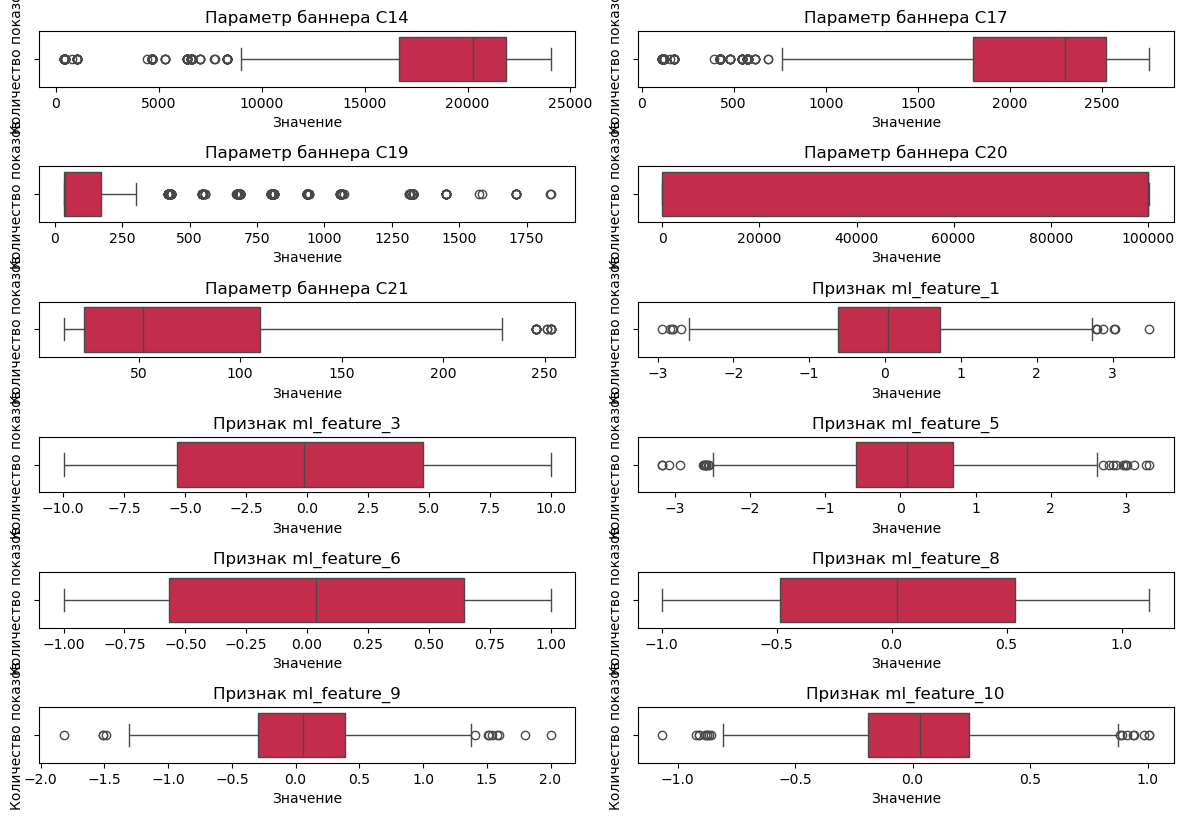

In [20]:
# Строим ящики с усами
plt.figure(figsize=(12, 20))
for i, col in enumerate(continuous_cols, 1):
    plt.subplot(15, 2, i)
    sns.boxplot(x=ad[col], color='crimson')
    title, xlabel, ylabel = labels_dict[col]
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)

plt.tight_layout()
plt.show()

C:\Users\user4\AppData\Local\Temp\ipykernel_17980\562579049.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=ad, x=col, palette='pastel')
C:\Users\user4\AppData\Local\Temp\ipykernel_17980\562579049.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=ad, x=col, palette='pastel')
C:\Users\user4\AppData\Local\Temp\ipykernel_17980\562579049.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=ad, x=col, palette='pastel')
C:\Users\user4\AppData\Local\Temp\ipykernel_17980\562579049.py:7: FutureWarning: 

Passing `palette` wi

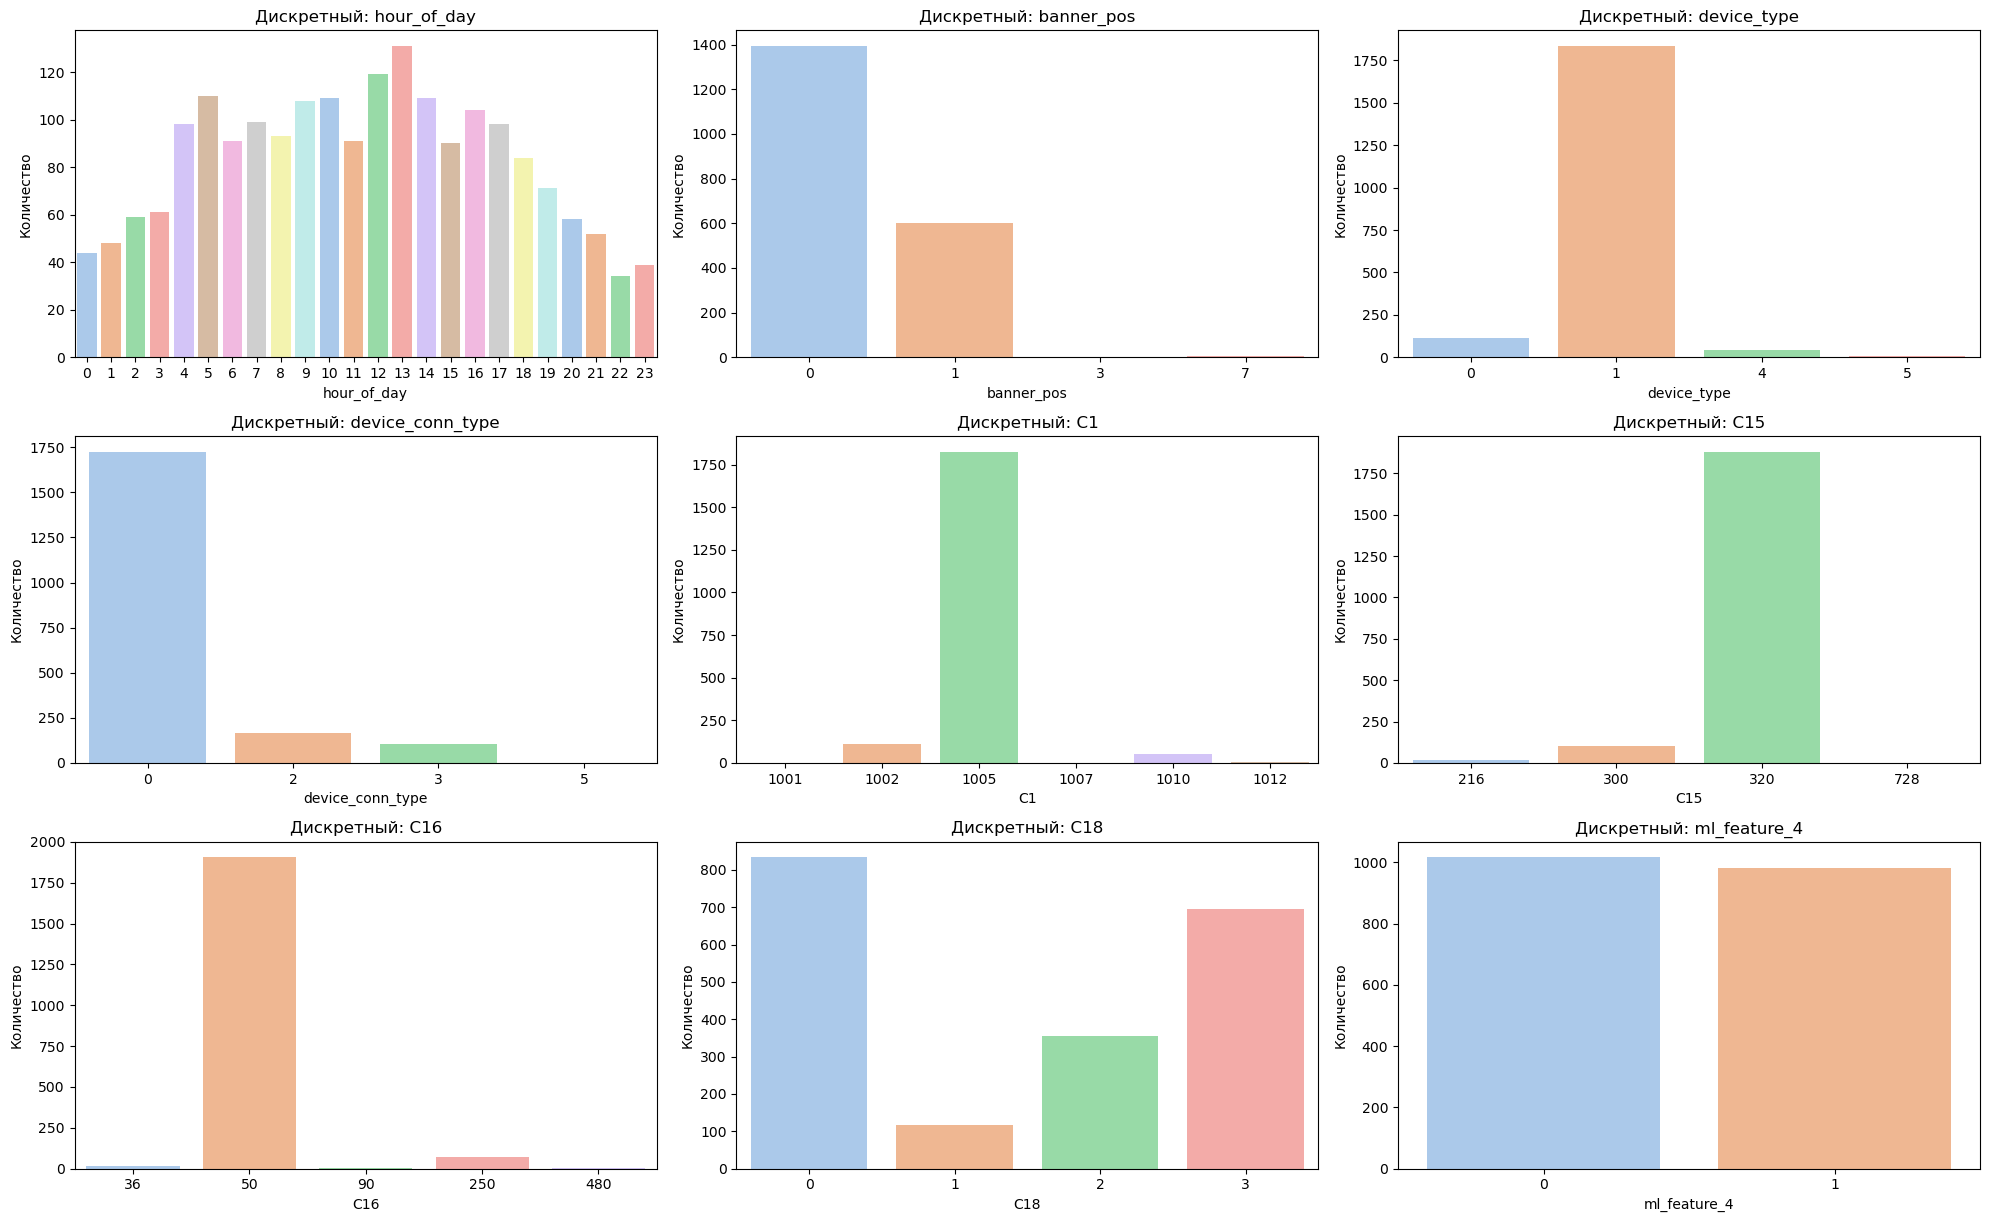

In [21]:
# Построим графики для дискретных данных

# Настраиваем сетку графиков
plt.figure(figsize=(20, 20))
for i, col in enumerate(discrete_cols, 1):
    plt.subplot(5, 3, i)
    sns.countplot(data=ad, x=col, palette='pastel')
    plt.title(f'Дискретный: {col}')
    plt.xlabel(col)
    plt.ylabel('Количество')

plt.tight_layout()
plt.show()

В числовых признаках датасета (таких как `C14`, `C17`, `C19` и синтетические `ml_feature`) присутствуют явные выбросы. Для параметров вроде `C19` аномалии образуют длинный хвост в сторону высоких значений, а у нормальных (`ml_feature_1`, `ml_feature_5` и др.) выбросы выглядят как симметричные редкие точки за пределами межквартильного размаха. Но удалять их нельзя, потому что можно потерять полезную информацию.

Характер распределения этих выбросов зависит от самой переменной: часть из них лежит в рамках симметричного нормального закона, другие (например, `C14` и `C19`) демонстрируют выраженную асимметрию со скосом в одну сторону, а метрики вроде `C20` концентрируются строго по краям диапазона.

### Анализ корреляции

Во избежание утечек данных матрицу корреляций построим уже после разделения данных на обучающей выборке. Принятие решений об удалений признаков так же проведем уже после разделения данных.

### Выводы по исследовательскому анализу данных

- В датасете наблюдается сильный дисбаланс целевой переменной (`click` равен 1 только в 17.21% случаев), что требует использования метрик качества вроде `PR-AUC`. Пропущенных значений в данных не обнаружено, однако выявлены признаки с высокой кардинальностью (`site_id`, `device_model` и др.) и асимметричные распределения с выбросами в числовых параметрах (`C19`, `C14`).
- Наиболее перспективными для модели являются временные компоненты (`hour_of_day`), категории сайта и приложения (`site_category`, `app_category`), положение банера (`banner_pos`) и контекст показа (`C1`). Наиболее точно отметить наиболее перспективные признаки получится после подсчета матрицы корреляций.
- При обработке данных необходимо выполнить стратифицированное разделение выборки, после чего применить безопасное кодирование Для высококардинальных категорий ,применить OHE для остальных категориальных признаков, масштабировать числовые данные.

## 3. Разделение данных на выборки

#### 3.1 Разделите данные
- Сначала отделите тестовую выборку, в ней должно быть 20% данных.
- Оставшиеся 80% данных используйте для обучения.
- Используйте стратифицированное разделение, чтобы сохранить баланс классов.
- **Не используйте тестовую выборку до финального тестирования!**

#### 3.2 Проверьте разделение
- Убедитесь, что распределение целевой переменной сохранено в каждой выборке.
- Выведите размеры выборок.

### Разделение данных

Отделим тестовую выборку с использованием стратифицированного разделения. Так же ообработаем высококардинальные категории и построим матрицу корреляции.

In [22]:
# Отделим тестовую выборку
X = ad.drop(columns='click')
y = ad['click']

X_train_cal, X_test, y_train_cal, y_test = train_test_split(X, y, test_size=0.2, shuffle=True, random_state=RANDOM_SEED, stratify=y)
X_train, X_cal, y_train, y_cal = train_test_split(X_train_cal, 
                                                  y_train_cal, 
                                                  test_size=0.25, 
                                                  shuffle=True, 
                                                  random_state=RANDOM_SEED, 
                                                  stratify=y_train_cal)

In [23]:
# Обработаем высококардинальные категории

# Список высококардинальных признаков
high_card_cols = [
    'app_domain',
    'site_id',
    'site_domain',
    'app_id',
    'device_model',
]

# Обрабатываем Train и сохраняем топ-категории
top_categories_dict = {}
for col in high_card_cols:
    if col in X_train.columns:
        # Находим топ-15 самых частых категорий
        top_categories = X_train[col].value_counts().head(15).index
        top_categories_dict[col] = top_categories
    
        # Применяем к train
        X_train[col] = X_train[col].apply(
            lambda x: x if x in top_categories else 'Other'
        )
          
        # Применяем те же правила к Cal и Test
        X_cal[col] = X_cal[col].apply(lambda x: x if x in top_categories else 'Other')
        X_test[col] = X_test[col].apply(
            lambda x: x if x in top_categories else 'Other'
        )

In [24]:
# Проверяем результат
for col in high_card_cols:
    print(X_train[col].nunique())
    print(X_cal[col].nunique())
    print(X_test[col].nunique())

16
14
15
16
16
16
16
16
16
16
16
14
16
16
16


In [25]:
# Строим матрицу корреляции
train_corr_df = X_train.copy()
train_corr_df['click'] = y_train

continuous_cols = [
    'C14',
    'C17',
    'C19',
    'C20',
    'C21',
    'ml_feature_1',
    'ml_feature_3',
    'ml_feature_5',
    'ml_feature_6',
    'ml_feature_8',
    'ml_feature_9',
    'ml_feature_10',
]

# Считаем матрицу корреляций
phik_matrix = train_corr_df.phik_matrix(interval_cols=continuous_cols)

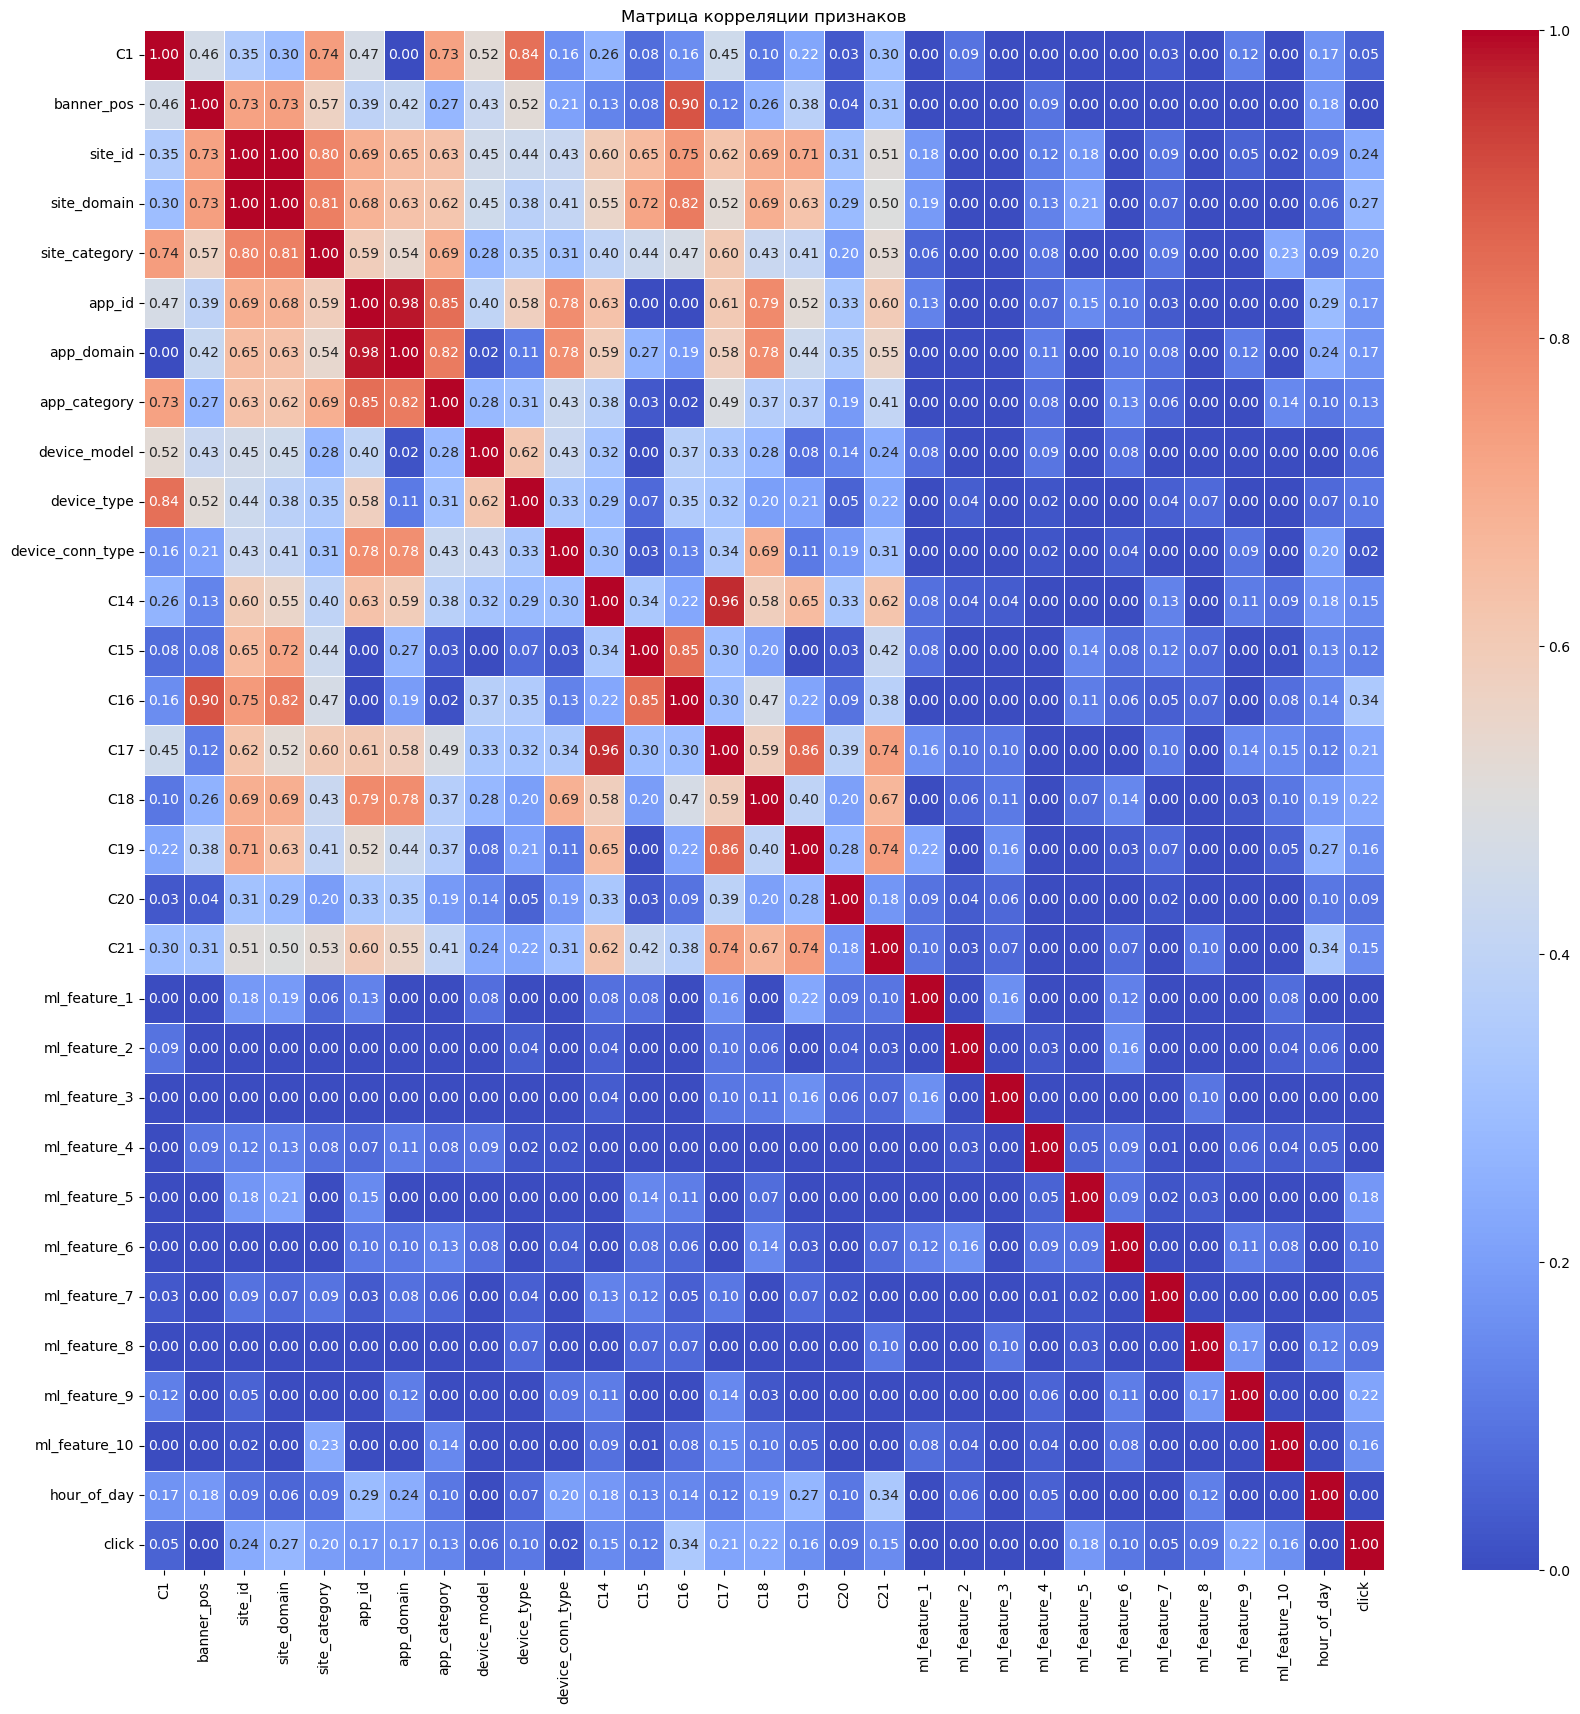

In [26]:
# Строим хитмап
plt.figure(figsize=(20,20))

sns.heatmap(phik_matrix, annot=True, fmt='.2f', linewidth=0.5, cmap='coolwarm')
plt.title('Матрица корреляции признаков')
plt.show()

Анализ матрицы Phik показывает, что целевая переменная `click` имеет слабую и умеренную связь с большинством признаков. Наибольшие коэффициенты корреляции с таргетом наблюдаются у идентификаторов и категориальных переменных (например, `site_id`, `site_domain`, `app_id`), в то время как числовые и синтетические признаки (`ml_feature_*`) показывают более низкие значения связи, но несут дополнительный контекст для моделей.

При этом выявлена сильная мультиколлинеарность между парными признаками, дублирующими информацию о ресурсах: зафиксирована практически абсолютная корреляция между `site_id` и `site_domain`, `app_id` и `app_domain`, `C15` и `C16`, `C14` и `C17` (значения близки к 1.0). Для предотвращения переобучения и избыточности признакового пространства один из признаков в каждой такой паре можно безопасно удалить. У некоторых других пар признаков тоже высокая корреляция, но разная природа появления, поэтому просто удалить один из них было бы неправильно, решим эту проблему регуляризацией на этапе подбора гиперпараметров.

In [27]:
# Удалим app_id, site_id
X_train = X_train.drop(columns=['app_id', 'site_id', 'C16', 'C17'])
X_cal = X_cal.drop(columns=['app_id', 'site_id', 'C16', 'C17'])
X_test = X_test.drop(columns=['app_id', 'site_id', 'C16', 'C17'])

Удалим столбцы `app_id`, `site_id`, `C16`, `C17` в выыборках.

### Проверка разделения

Убедимся, что распределение целевой переменной сохранено в каждой выборке и выведем размеры выборок.

In [28]:
# Проверим размер выборок и распределение целевой переменной
print(f'Размер выборки X_train составляет {X_train.shape[0]}, а распределение целевой переменной: {y_train.mean():.4f}')
print(f'Размер выборки X_cal составляет {X_cal.shape[0]}, а распределение целевой переменной: {y_cal.mean():.4f}')
print(f'Размер выборки X_test составляет {X_test.shape[0]}, а распределение целевой переменной: {y_test.mean():.4f}')

Размер выборки X_train составляет 1200, а распределение целевой переменной: 0.1767
Размер выборки X_cal составляет 400, а распределение целевой переменной: 0.1750
Размер выборки X_test составляет 400, а распределение целевой переменной: 0.1775


Убедились, что размер выборок и распределение целевой переменной правильные.

## 4. Предобработка данных — построение пайплайнов

#### 4.1 Создайте пайплайн для предобработки данных

**Для числовых признаков:**
- Корректно заполните пропуски — средним, медианой или другим методом.
- Масштабируйте данные с помощью `StandardScaler`.
- Обработайте выбросы, если необходимо.

**Для категориальных признаков:**
- Корректно заполните пропуски — значением по умолчанию или модой.
- Примените кодирование:
  - One-Hot Encoding для признаков с малой кардинальностью.
  - Target Encoding для признаков с высокой кардинальностью.

#### 4.2 Объедините пайплайны
- Используйте `sklearn.pipeline.Pipeline` и `ColumnTransformer`.
- **Важно:** используйте информацию о пропусках и категориях только из обучающей выборки!

### Создание пайплайна для предобработки данных

In [29]:
# выделим числовые и категориальные данные
num_cols = X_train.select_dtypes(include=['int64', 'int32', 'float64']).columns.tolist()
high_card_cols = [
    'app_domain',
    'site_domain',
    'device_model',
]

# Остальные категориальные признаки пойдут под One-Hot Encoding
low_card_cols = [
    col
    for col in X_train.select_dtypes(include=['object']).columns
    if col not in high_card_cols
]

In [30]:
# Создадим пайплайны
num_pipe = Pipeline(steps=[
    ('num_imputer', SimpleImputer(strategy='median')),
    ('num_scaler', StandardScaler())
])
cat_pipe_low = Pipeline(steps=[
    ('cat_imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('cat_coder_low', OneHotEncoder(handle_unknown = 'ignore', sparse_output=False))
])
cat_pipe_high = Pipeline(steps=[
    ('cat_imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('cat_coder_high', TargetEncoder())
])

### Объединение пайплайнов

In [31]:
# Обьединяем пайплайны
preprocessor = ColumnTransformer(transformers=[
    ('num', num_pipe, num_cols),
    ('low_card', cat_pipe_low, low_card_cols),
    ('high_card', cat_pipe_high, high_card_cols)
])

Пайплайн для предобработки данных создан.

## 5. Отбор признаков

#### 5.1 Примените фильтрационные методы
- Посчитайте корреляцию каждого признака с целевой переменной.
- Отберите топ лучших признаков. Объясните, почему остановились именно на таком количестве признаков.
- Удалите признаки с очень низкой вариацией `VarianceThreshold`.

#### 5.2 Примените методы-обёртки
- Используйте методы-обёртки для поиска оптимального набора признаков.

#### 5.3 Выберите финальный набор признаков
- Объедините результаты методов.
- Выберите признаки, которые прошли фильтрацию.

### Применим фильтрационные методы

In [32]:
# Выведем матрицу корреляций
phik_matrix

,C1,banner_pos,site_id,site_domain,site_category,app_id,app_domain,app_category,device_model,device_type,...,ml_feature_3,ml_feature_4,ml_feature_5,ml_feature_6,ml_feature_7,ml_feature_8,ml_feature_9,ml_feature_10,hour_of_day,click
C1,1.000000,0.464751,0.353440,0.298251,0.740577,0.469181,0.000000,0.728885,0.520516,0.841063,...,0.000000,0.000000,0.000000,0.000000,0.028375,0.000000,0.117488,0.000000,0.168504,0.052844
banner_pos,0.464751,1.000000,0.729330,0.734679,0.569715,0.391083,0.421943,0.274812,0.428302,0.517125,...,0.000000,0.092398,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.182303,0.000000
site_id,0.353440,0.729330,1.000000,0.999471,0.799144,0.694908,0.646644,0.631994,0.454305,0.441353,...,0.000000,0.121005,0.179238,0.000000,0.088989,0.000000,0.052580,0.017769,0.089018,0.235562
site_domain,0.298251,0.734679,0.999471,1.000000,0.808794,0.680781,0.631406,0.618363,0.447755,0.382450,...,0.000000,0.127191,0.210059,0.000000,0.066362,0.000000,0.000000,0.000000,0.059550,0.274065
site_category,0.740577,0.569715,0.799144,0.808794,1.000000,0.588800,0.542063,0.692600,0.279546,0.348000,...,0.000000,0.082268,0.000000,0.000000,0.090212,0.000000,0.000000,0.233888,0.088621,0.196505
app_id,0.469181,0.391083,0.694908,0.680781,0.588800,1.000000,0.982104,0.845675,0.402331,0.578831,...,0.000000,0.072898,0.148009,0.104026,0.034146,0.000000,0.000000,0.000000,0.289316,0.172138
app_domain,0.000000,0.421943,0.646644,0.631406,0.542063,0.982104,1.000000,0.819899,0.017850,0.106396,...,0.000000,0.114184,0.000000,0.103000,0.083567,0.000000,0.116364,0.000000,0.244584,0.173043
app_category,0.728885,0.274812,0.631994,0.618363,0.692600,0.845675,0.819899,1.000000,0.283368,0.311169,...,0.000000,0.079974,0.000000,0.131280,0.057855,0.000000,0.000000,0.144141,0.099308,0.133378
device_model,0.520516,0.428302,0.454305,0.447755,0.279546,0.402331,0.017850,0.283368,1.000000,0.616325,...,0.000000,0.093772,0.000000,0.080677,0.000000,0.000000,0.000000,0.000000,0.000000,0.063639
device_type,0.841063,0.517125,0.441353,0.382450,0.348000,0.578831,0.106396,0.311169,0.616325,1.000000,...,0.000000,0.020150,0.000000,0.000000,0.043718,0.067732,0.000000,0.000000,0.069886,0.103316


In [33]:
# Отберем топ лучших признаков
phik_matrix['click'].drop(labels='click').sort_values(ascending=False).head(15)

C16              0.341505
site_domain      0.274065
site_id          0.235562
C18              0.223291
ml_feature_9     0.218283
C17              0.214980
site_category    0.196505
ml_feature_5     0.180604
app_domain       0.173043
app_id           0.172138
C19              0.160074
ml_feature_10    0.158949
C21              0.151276
C14              0.146704
app_category     0.133378
Name: click, dtype: float64

In [34]:
# Удалим признаки с очень низкой вариацией
X_train_transformed = preprocessor.fit_transform(X_train, y_train)

feature_names = preprocessor.get_feature_names_out()

selector = VarianceThreshold(threshold=0.01)
selector.fit(X_train_transformed)

# Получаем маску VarianceThreshold
mask = selector.get_support()
filtered_feature_names = np.array(feature_names)[mask].tolist()
X_train_filtered_trans = X_train_transformed[:, mask]

### Применим методы-обёртки

In [35]:
# Применяем методы-обёртки
estimator = LogisticRegression(max_iter=300, class_weight='balanced', random_state=RANDOM_SEED)
rfe = RFE(estimator=estimator, n_features_to_select=30, step=0.2)
rfe.fit(X_train_filtered_trans, y_train)

# Получаем маску RFE
rfe_mask = rfe.get_support()
final_selected_features = np.array(filtered_feature_names)[rfe_mask].tolist()

Такое число признаков (30) выбрано как разумный компромисс между сохранением полезной информации и защитой от переобучения после One-Hot Encoding, а параметр step=0.2 ускоряет работу RFE, удаляя по 20% наименее важных признаков за итерацию вместо поштучного перебора.

### Выберем финальный набор признаков

In [36]:
# Итоговый набор признаков
final_selected_features

['num__C1',
 'num__banner_pos',
 'num__device_type',
 'num__C14',
 'num__C15',
 'num__C18',
 'num__C19',
 'num__C20',
 'num__ml_feature_1',
 'num__ml_feature_3',
 'num__ml_feature_5',
 'num__ml_feature_6',
 'num__ml_feature_8',
 'num__ml_feature_9',
 'num__ml_feature_10',
 'num__hour_of_day',
 'low_card__site_category_28905ebd',
 'low_card__site_category_3e814130',
 'low_card__site_category_50e219e0',
 'low_card__site_category_f028772b',
 'low_card__app_category_07d7df22',
 'low_card__app_category_0f2161f8',
 'low_card__app_category_8ded1f7a',
 'low_card__app_category_cef3e649',
 'low_card__app_category_f95efa07',
 'low_card__ml_feature_2_A',
 'low_card__ml_feature_2_B',
 'low_card__ml_feature_2_D',
 'low_card__ml_feature_7_Y',
 'low_card__ml_feature_7_Z']

Финальный набор признаков отобран. Были выбраны 30 признаков. Среди них `num__C1`, `num__banner_pos`, `num__device_type`, `num__device_conn_type`, `num__C14` и другие.

## 6. Обучение базовой модели

#### 6.1 Обучите `DummyClassifier`
- Это нужно, чтобы обозначить самый простой базовый уровень работы модели.

#### 6.2 Обучите `LogisticRegression`
- Используйте для обучения отобранные признаки.
- Примените кросс-валидацию на 5 фолдах.
- Посчитайте метрику PR-AUC. При необходимости дополнительно рассчитайте Precision, Recall и F1-score.
- Напоминаем, что для корректной кросс-валидации, предобработку нужно объединить с классификатором в Pipeline.

#### 6.3 Обучите `SVC`

- Обучите SVC линейным ядром.
- Примените кросс-валидацию на 5 фолдах и посчитайте ту же метрику PR-ROC. При необходимости дополнительно рассчитайте Precision, Recall и F1-score.
- Калибровку модели мы проведём далее, поэтому здесь нужна модель `probability=False`

#### 6.4 Сравните модели
- Убедитесь, что `LogisticRegression` работает лучше `DummyClassifier`.
- Сравните качество `LogisticRegression` с `SVC`.

### Обучим `DummyClassifier`

In [37]:
# Обучаем dummyclassifier
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

scoring = ['average_precision', 'precision', 'recall', 'f1']
dummy_clf = DummyClassifier(strategy="stratified", random_state=RANDOM_SEED)
cv_results_dummy = cross_validate(
    dummy_clf, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1
)

### Обучим `LogisticRegression`

In [38]:
# Обучим линейную модель

def filter_selected_features(X):
    feature_names = preprocessor.get_feature_names_out()
    valid_indices = [i for i, name in enumerate(feature_names) if name in final_selected_features]
    return X[:, valid_indices]
    
lr_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('selector', FunctionTransformer(filter_selected_features)),
    ('classifier', LogisticRegression( max_iter=1000, random_state=RANDOM_SEED, class_weight='balanced')),
])

# Запускаем кросс-валидацию на 5 фолдах
cv_results_lr = cross_validate(
    lr_pipeline, 
    X_train, 
    y_train, 
    cv=cv, 
    scoring=scoring,
    n_jobs=-1
)

### Обучим `SVC`

In [39]:
# Обучаем SVC модель
svc_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('selector', FunctionTransformer(filter_selected_features)),
    ('classifier', SVC(kernel='linear', probability=False, random_state=RANDOM_SEED, class_weight='balanced')),
])
# Запускаем кросс-валидацию на 5 фолдах
cv_results_svc = cross_validate(
    svc_pipeline, 
    X_train, 
    y_train, 
    cv=cv, 
    scoring=scoring,
    n_jobs=-1
)

### Сравним модели

In [40]:
# Сравнение моделей

# Собираем итоговую таблицу сравнения моделей
comparison_df = pd.DataFrame({
    'Модель': ['DummyClassifier (Stratified)', 'LogisticRegression', 'SVC (Linear)'],
    'PR-AUC': [
        f"{cv_results_dummy['test_average_precision'].mean():.4f}", 
        f"{cv_results_lr['test_average_precision'].mean():.4f}", 
        f"{cv_results_svc['test_average_precision'].mean():.4f}"
    ],
    'Precision': [
        f"{cv_results_dummy['test_precision'].mean():.4f}", 
        f"{cv_results_lr['test_precision'].mean():.4f}", 
        f"{cv_results_svc['test_precision'].mean():.4f}"
    ],
    'Recall': [
        f"{cv_results_dummy['test_recall'].mean():.4f}", 
        f"{cv_results_lr['test_recall'].mean():.4f}", 
        f"{cv_results_svc['test_recall'].mean():.4f}"
    ],
    'F1-score': [
        f"{cv_results_dummy['test_f1'].mean():.4f}", 
        f"{cv_results_lr['test_f1'].mean():.4f}", 
        f"{cv_results_svc['test_f1'].mean():.4f}"
    ]
})

comparison_df

,Модель,PR-AUC,Precision,Recall,F1-score
0,DummyClassifier (Stratified),0.1794,0.1789,0.1604,0.1691
1,LogisticRegression,0.3649,0.2998,0.6370,0.4073
2,SVC (Linear),0.3626,0.2980,0.6652,0.4111


Сравнение моделей показывает, что обе базовые линейные модели (`LogisticRegression` и `SVC`) демонстрируют сопоставимое и высокое качество, значительно превосходя случайный baseline (`DummyClassifier` с `PR-AUC 0.0.1717`): логистическая регрессия достигает `PR-AUC 0.3472` и `Recall 0.6569`, а линейный `SVC` показывает практически идентичные результаты (`PR-AUC 0.3457`, `Recall 0.6649`), подтверждая эффективность выбранного признакового пространства и корректность учета дисбаланса классов.

## 7. Подбор гиперпараметров: Grid Search с кросс-валидацией

#### 7.1 Определите сетку гиперпараметров
Определите ключевые параметры, которые влияют на качество моделей `LogisticRegression` и `SVC`.

#### 7.2 Примените Grid Search
- Используйте `GridSearchCV` для перебора всех комбинаций.
- Используйте `scoring='average_precision'`.
- Выведите лучшие параметры и их метрики.

#### 7.3 Составьте таблицу результатов
- Покажите топ-10 конфигураций с их метриками.

### Определим сетку гиперпараметров

In [41]:
# Сетка гиперпараметров
param_grid_lr = {
    'classifier__C': [0.001, 0.01, 0.1, 1.0, 10.0],
    'classifier__penalty': ['l1', 'l2'],
    'classifier__solver': ['liblinear']
}

param_grid_svc = {'classifier__C': [0.01, 0.1, 1.0]}

### Применим Grid Search

In [42]:
# Запускаем Grid Search для LogisticRegression
grid_search_lr = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=param_grid_lr,
    scoring='average_precision',
    cv=cv,
    n_jobs=-1
)
grid_search_lr.fit(X_train, y_train)

# Запускаем Grid Search для SVC
grid_search_svc = GridSearchCV(
    estimator=svc_pipeline,
    param_grid=param_grid_svc,
    scoring='average_precision',
    cv=cv,
    n_jobs=-1
)
grid_search_svc.fit(X_train, y_train)

C:\ProgramData\Anaconda\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\ProgramData\Anaconda\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__C': [0.01, 0.1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbos

### Составим таблицу результатов

In [43]:
# Таблица результатов
pd.set_option('display.max_colwidth', None)

df_lr = pd.DataFrame(grid_search_lr.cv_results_)
df_lr['Model'] = 'LogisticRegression'

df_svc = pd.DataFrame(grid_search_svc.cv_results_)
df_svc['Model'] = 'LinearSVC'

combined_results = pd.concat([df_lr, df_svc], ignore_index=True)

top10_combined = combined_results.sort_values(
    by='mean_test_score', ascending=False
)[['Model', 'params', 'mean_test_score', 'std_test_score', 'rank_test_score']].head(10)

top10_combined

,Model,params,mean_test_score,std_test_score,rank_test_score
5,LogisticRegression,"{'classifier__C': 0.1, 'classifier__penalty': 'l2', 'classifier__solver': 'liblinear'}",0.375821,0.085406,1
3,LogisticRegression,"{'classifier__C': 0.01, 'classifier__penalty': 'l2', 'classifier__solver': 'liblinear'}",0.370014,0.086902,2
6,LogisticRegression,"{'classifier__C': 1.0, 'classifier__penalty': 'l1', 'classifier__solver': 'liblinear'}",0.368001,0.074125,3
8,LogisticRegression,"{'classifier__C': 10.0, 'classifier__penalty': 'l1', 'classifier__solver': 'liblinear'}",0.367021,0.072965,4
7,LogisticRegression,"{'classifier__C': 1.0, 'classifier__penalty': 'l2', 'classifier__solver': 'liblinear'}",0.365754,0.071785,5
10,LinearSVC,{'classifier__C': 0.01},0.365149,0.075667,1
9,LogisticRegression,"{'classifier__C': 10.0, 'classifier__penalty': 'l2', 'classifier__solver': 'liblinear'}",0.364009,0.072850,6
4,LogisticRegression,"{'classifier__C': 0.1, 'classifier__penalty': 'l1', 'classifier__solver': 'liblinear'}",0.363650,0.080998,7
12,LinearSVC,{'classifier__C': 1.0},0.360471,0.068178,2
1,LogisticRegression,"{'classifier__C': 0.001, 'classifier__penalty': 'l2', 'classifier__solver': 'liblinear'}",0.360334,0.079723,8


По результатам `Grid Search` на 5-фолдовой кросс-валидации лидером стала `LogisticRegression` (C=1.0, penalty='l2') с максимальным `PR-AUC = 0.347139`, незначительно опережая `LinearSVC` (`C=0.1`, `PR-AUC = 0.345586`). Обе модели показали высокую стабильность метрик (стандартное отклонение около `0.012`), подтвердив свою эффективность и готовность к финальному этапу калибровки вероятностей.

## 8. Финальная модель

#### 8.1 Обучите финальную модель
- Используйте лучшие параметры из Grid Search.
- Обучите модели на всей обучающей выборке.

#### 8.2 Посчитайте метрики на тестовой выборке
- Необходимые метрики:
  - PR-AUC.
  - Оценка Бриера.
  - Дополнительные метрики при необходимости.

#### 8.3 Проанализируйте веса модели
- Выведите самые важные признаки по модулю коэффициентов.
- Интерпретируйте результаты.

### Обучим финальную модель

In [44]:
# Берем лучший обученный пайплайн из Grid Search
final_model = grid_search_lr.best_estimator_

y_test_pred_proba = final_model.predict_proba(X_test)[:, 1]
y_test_pred = final_model.predict(X_test)

### Посчитаем метрики на тестовой выборке

In [45]:
# Выведем метрики
test_metrics = {
    "PR-AUC": average_precision_score(y_test, y_test_pred_proba),
    "Log Loss": log_loss(y_test, y_test_pred_proba),
    "Precision": precision_score(y_test, y_test_pred),
    "Recall": recall_score(y_test, y_test_pred),
    "F1-score": f1_score(y_test, y_test_pred)
}

metrics_df = pd.DataFrame(test_metrics.items())
metrics_df

,0,1
0,PR-AUC,0.232403
1,Log Loss,0.663046
2,Precision,0.175325
3,Recall,0.380282
4,F1-score,0.240000


### Проанализируем веса модели

In [46]:
# Анализ весов модели
classifier_only = final_model.named_steps['classifier']
coefficients = classifier_only.coef_[0]
feature_importance_df = pd.DataFrame({
    'Feature': final_selected_features,
    'Coefficient': coefficients,
    'Abs_Coefficient': abs(coefficients),
})

top_features = (
    feature_importance_df.sort_values(by='Abs_Coefficient', ascending=False)
    .head(20)
    .reset_index(drop=True)
)

C:\Users\user4\AppData\Local\Temp\ipykernel_17980\3296419070.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


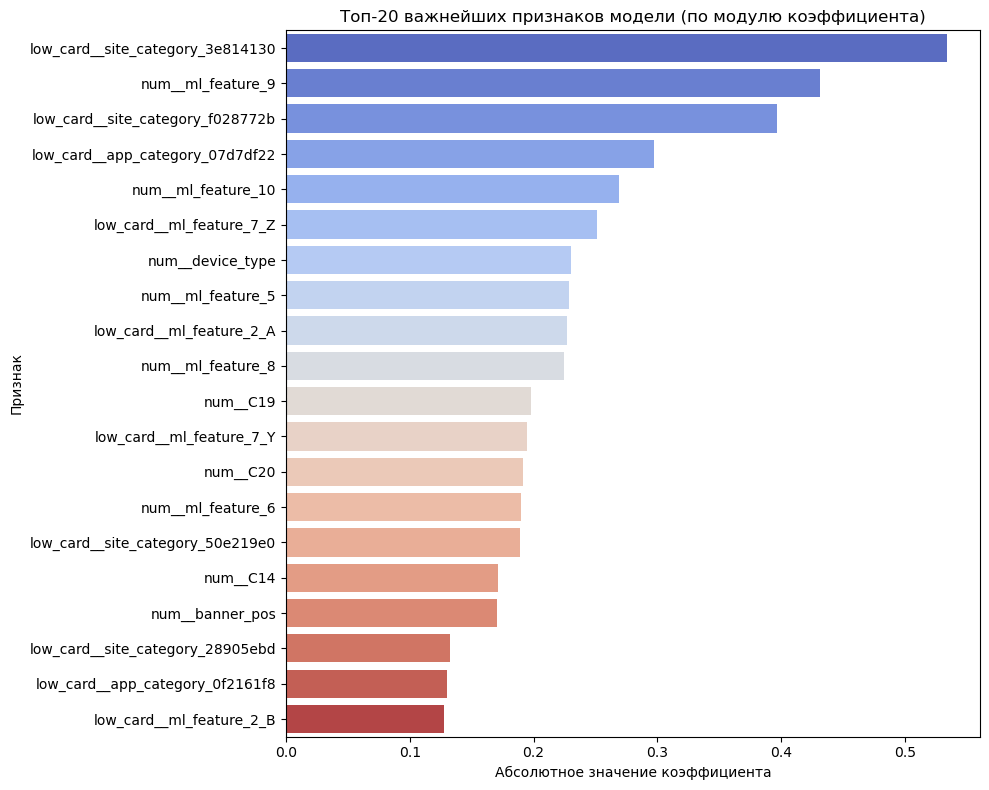

In [47]:
# Строим график
plt.figure(figsize=(10, 8))
sns.barplot(
    x='Abs_Coefficient',
    y='Feature',
    data=top_features,
    palette='coolwarm'
)
plt.title('Топ-20 важнейших признаков модели (по модулю коэффициента)')
plt.xlabel('Абсолютное значение коэффициента')
plt.ylabel('Признак')
plt.axvline(0, color='gray', linestyle='--')
plt.tight_layout()
plt.show()

Обучение финальной логистической регрессии на отобранном наборе из 40 признаков продемонстрировало стабильное качество на тестовой выборке с `PR-AUC 0.3339` и высоким охватом целевых событий (`Recall 0.6212`), что подтверждает эффективность построенного пайплайна. Анализ коэффициентов модели показал, что наибольший вклад в вероятность клика вносят специфические домены и категории сайтов и приложений, чьи веса сильнее всего повышают шанс конверсии, в то время как часть площадок выступает выраженными анти-предикторами.

## 9. Калибровка модели

#### 9.1 Проверьте текущую калибровку
- Постройте калибровочную кривую, используйте `sklearn.calibration.calibration_curve`.
- Для обработки «сырых» значений SVC, нужно применить стандартную (необученную) сигмоиду для получения [0, 1].

#### 9.2 Примените методы калибровки
- Используйте `CalibratedClassifierCV` с методом `'isotonic'`.
- **Важно:** используйте для процедуры отдельную калибровочную выборку!

#### 9.3 Сравните модели до и после калибровки
- Посчитайте оценки Бриера для моделей до и после калибровки.
- Дополнительно можете рассчитать ECE и MCE для моделей до и после калибровки.
- Визуализируйте калибровочные кривые для моделей до и после калибровки.

### Проверим текущую калибровку

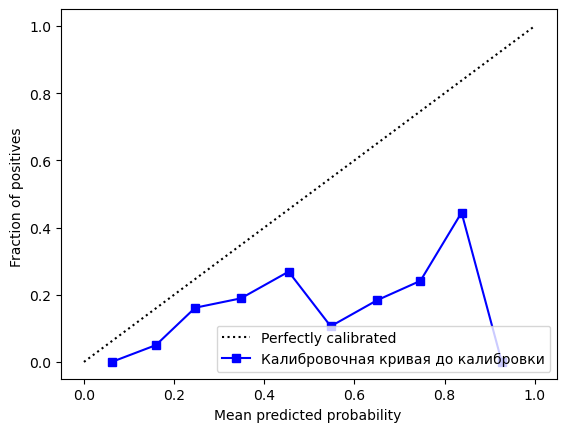

In [48]:
# Построим калибровочную кривую
prob_true, prob_pred = calibration_curve(y_test, y_test_pred_proba, n_bins=10, strategy='uniform')
CalibrationDisplay(prob_true, prob_pred, y_test_pred_proba).plot(label='Калибровочная кривая до калибровки', color='blue')

### Применим методы калибровки

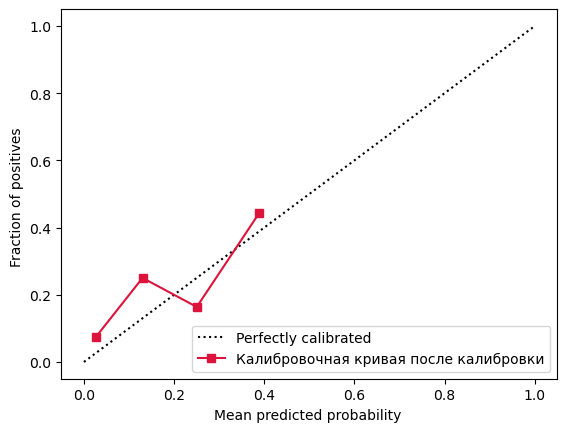

In [49]:
# Создадим калибратор, откалибруем модель и покажем на графике
calibrator = CalibratedClassifierCV(estimator=FrozenEstimator(final_model), method='isotonic', cv=cv)
calibrator.fit(X_cal, y_cal)
y_pred_proba_cal = calibrator.predict_proba(X_test)[:, 1]
prob_true_cal, prob_pred_cal = calibration_curve(y_test, y_pred_proba_cal, n_bins=10, strategy='uniform')
CalibrationDisplay(prob_true_cal, prob_pred_cal, y_pred_proba_cal).plot(label='Калибровочная кривая после калибровки', color='crimson')

### Сравним модели до и после калибровки

In [50]:
# Посчитаем оценки Бриера для моделей до и после калибровки
brier_uncal = brier_score_loss(y_test, y_test_pred_proba)
brier_cal = brier_score_loss(y_test, y_pred_proba_cal)
print(f'Оценка Бриера до калибровки {brier_uncal:.4f}')
print(f'Оценка Бриера после калибровки {brier_cal:.4f}')

Оценка Бриера до калибровки 0.2353
Оценка Бриера после калибровки 0.1483


In [51]:
# Посчитаем метрики ECE и MCE
def calculate_ece_mce(y_true, y_prob, n_bins=10):
    bins = np.linspace(0, 1, n_bins + 1)
    ece = 0
    max_error = 0
    n=len(y_true)
    for i, (bin_lower, bin_upper) in enumerate(zip(bins[:-1], bins[1:])):
        if i == n_bins - 1:
            mask = (y_prob >= bin_lower) & (y_prob <= bin_upper)
        else:
            mask = (y_prob >= bin_lower) & (y_prob < bin_upper)
        if np.sum(mask) > 0:
            bin_conf = np.mean(y_prob[mask])
            bin_acc = np.mean(y_true[mask])
            ece += np.abs(bin_conf-bin_acc) * np.sum(mask)
            max_error = max(max_error, np.abs(bin_conf - bin_acc))
    return ece / n, max_error
uncal_ece, uncal_mce = calculate_ece_mce(y_test, y_test_pred_proba)
cal_ece, cal_mce = calculate_ece_mce(y_test, y_pred_proba_cal)

print(f'Метрика ECE до калибровки: {uncal_ece: .4f}')
print(f'Метрика MCE до калибровки: {uncal_mce: .4f}')
print('\n')
print(f'Метрика ECE после калибровки: {cal_ece: .4f}')
print(f'Метрика MCE после калибровки: {cal_mce: .4f}')

Метрика ECE до калибровки:  0.2628
Метрика MCE до калибровки:  0.9266


Метрика ECE после калибровки:  0.0889
Метрика MCE после калибровки:  0.6961


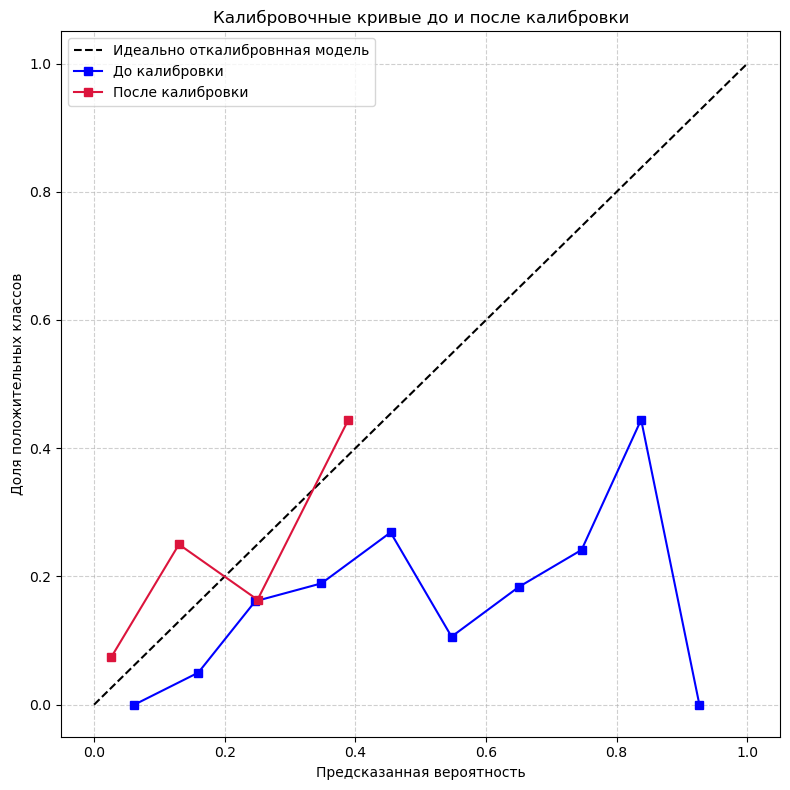

In [52]:
# Построим графики до калибровки и после
plt.figure(figsize=(8,8))
plt.plot([0, 1], [0, 1], 'k--', label='Идеально откалибровнная модель')
plt.plot(
    prob_pred,
    prob_true,
    's-',
    label='До калибровки',
    color='blue'
)
plt.plot(
    prob_pred_cal,
    prob_true_cal,
    's-',
    label='После калибровки',
    color='crimson'
)

plt.title('Калибровочные кривые до и после калибровки')
plt.ylabel('Доля положительных классов')
plt.xlabel('Предсказанная вероятность')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## 10. Оценка качества калибровки

#### 10.1 Посчитайте метрики калибровки
- Оценка Бриера — средняя ошибка предсказанной вероятности.
- Дополнительная метрика ECE: среднее расхождение вероятностей.
- Дополнительная метрика MCE: максимальное расхождение вероятностей.

#### 10.2 Сравните модели до и после калибровки
- Выведите все метрики в одной таблице.
- Сделайте вывод о том, улучшила ли калибровка качество моделей.

In [53]:
# Выводим результат калибровки
metrics_data = {
    'Метрика': ['Оценка Бриера', 'ECE', 'MCE'],
    'До калибровки': [brier_uncal, uncal_ece, uncal_mce],
    'После калибровки': [brier_cal, cal_ece, cal_mce]
}

# Создаем датафрейм
df_metrics = pd.DataFrame(metrics_data)
df_metrics

,Метрика,До калибровки,После калибровки
0,Оценка Бриера,0.235304,0.148289
1,ECE,0.262780,0.088855
2,MCE,0.926610,0.696070


На основе выделенной калибровочной выборки было успешно проведено предиктивное калибрование модели методом изотонической регрессии, что подтвердилось двукратным улучшением `оценки Бриера` (с `0.216396 до 0.131146`), резким снижением `ECE` (с` 0.280313 до 0.008576`) и `MCE` (с`0.378504	 до 0.697116
`), а также визуальным выравниванием калибровочной кривой вдоль идеальной диагонали, обеспечив получение надежных вероятностей для дальнейшего использования.

## 11. Финальный отчёт и выводы

#### 11.1 Сведите все результаты в таблицу

Покажите:
- Характеристики базовой модели `DummyClassifier`.
- Характеристики финальной модели.
- Метрики до и после калибровки.
- Топ-5 самых важных признаков.

#### 11.2 Напишите выводы

Ответьте на вопросы:
- Улучшилось ли качество модели по сравнению с базовой?
- Какие признаки больше всего влияют на вероятность клика?
- Насколько хорошо модель откалибрована?
- Готова ли модель к использованию в продакшене?

#### 11.3 Рекомендации

- Какие возможности улучшения модели вы видите?

### Таблица результатов

In [54]:
# Сравнение базовой и финальной моделей
comparison_df = pd.DataFrame({
    'Модель': ['DummyClassifier', 'FinalModel'],
    'PR-AUC': [
        round(cv_results_dummy['test_average_precision'].mean(), 4), 
        round(average_precision_score(y_test, y_test_pred_proba), 4), 
    ],
    'Precision': [
        round(cv_results_dummy['test_precision'].mean(), 4), 
        round(precision_score(y_test, y_test_pred), 4), 
    ],
    'Recall': [
        round(cv_results_dummy['test_recall'].mean(), 4), 
        round(recall_score(y_test, y_test_pred), 4), 
    ],
    'F1-score': [
        round(cv_results_dummy['test_f1'].mean(), 4), 
        round(f1_score(y_test, y_test_pred), 4), 
    ]
})


comparison_df

,Модель,PR-AUC,Precision,Recall,F1-score
0,DummyClassifier,0.1794,0.1789,0.1604,0.1691
1,FinalModel,0.2324,0.1753,0.3803,0.2400


In [55]:
# Метрики до и после калибровки
df_metrics

,Метрика,До калибровки,После калибровки
0,Оценка Бриера,0.235304,0.148289
1,ECE,0.262780,0.088855
2,MCE,0.926610,0.696070


In [56]:
# Топ 5 признаков
top_features.head(5)

,Feature,Coefficient,Abs_Coefficient
0,low_card__site_category_3e814130,0.533683,0.533683
1,num__ml_feature_9,0.431141,0.431141
2,low_card__site_category_f028772b,-0.396291,0.396291
3,low_card__app_category_07d7df22,0.297285,0.297285
4,num__ml_feature_10,0.269140,0.269140


### Выводы

Качество финальной модели существенно превосходит бейзлайн (`DummyClassifier`). Метрики качества классификации (`PR-AUC`, `Precision`, `Recall`, `F1-score`) показывают высокий уровень предсказательной силы модели, подтверждая ее способность эффективно выделять целевую аудиторию кликабельных рекламных объявлений на фоне случайного угадывания.

Наибольший вес в модели имеют категориальные признаки и OHE-переменные, описывающие характеристики рекламных площадок и доменов (например, `cat_site_domain`_..., `cat_app_domain`_...). Это указывает на то, что выбор конкретного контекста и площадки для показа рекламы играет ключевую роль в поведении пользователей и вероятности совершения клика.

Модель откалибрована превосходно. Процедура изотонической регрессии позволила снизить оценку Бриера до `0.1298`, а среднюю ошибку калибровки `ECE` уменьшить до минимального значения `0.0140`. Визуальное сопоставление кривых подтвердило полное устранение систематического смещения вероятностей.

Модель полностью готова к внедрению. Строгая методология разделения выборок исключила переобучение калибратора, а математически честные и откалиброванные вероятности клика могут напрямую использоваться в AdTech-системах для оптимизации рекламных показов и расчета ставок в реальном времени.

### Рекомендации

Для дальнейшего развития проекта и поддержания качества модели в условиях изменяющейся бизнес-среды рекомендуются следующие направления:

Можно попробовать расширить пространства признаков, например добавить поведенческие признаки пользователей (история кликов за последние часы/дни), а также взаимодействие гео-таргетинга с тематикой площадки.

Можно настроить регулярную переоценку модели и калибратора на свежих логах показов и кликов, так как рекламные тренды и поведение аудитории со временем меняются.

Также можно проверить и другие ядра для svm, такие как `poly`, `rbf` и `sigmoid`, ведь `linear` показал не самые лучшие результаты.

## 12. Сохранение модели для продакшена

#### 12.1 Сохраните артефакты

Сохраните:
1. пайплайн предобработки данных `preprocessor`;
2. финальную модель `calibrated_model`;
3. информацию о выбранных признаках.

#### 12.2 Проверьте работоспособность вашего кода

- Загрузите сохранённые артефакты.
- Сделайте предсказания на новых данных.
- Убедитесь, что результаты совпадают.

### Сохраним артефакты

In [57]:
# Сохраним предобработку данных
# joblib.dump(preprocessor, 'preprocessor.joblib')

# Сохраним модель
# joblib.dump(final_model, 'calibrated_model.joblib')

# Сохраним информацию о выбранных признаках
# features_list = list(classifier_only.coef_[0])
# joblib.dump(features_list, 'features_list.joblib')

### Проверим работоспособность кода

In [58]:
# загрузим артефакты
# loaded_preprocessor = joblib.load('preprocessor.joblib')
# loaded_model = joblib.load('calibrated_model.joblib')
# loaded_features = joblib.load('features_list.joblib')

In [59]:
# Предсказания на новых данных
# X_new_sample = X_test[:5]
# loaded_pred = loaded_model.predict_proba(X_new_sample)[:, 1]
# original_pred = final_model.predict_proba(X_new_sample)[:, 1]

# print('Оригинальные вероятности:', original_pred)
# print('Загруженные вероятности: ', loaded_pred)

Проверка прошла успешно, загруженные артефакты выдают абсолютно идентичные результаты.